# Project 2: Clustering gene expression data

In this notebook I compare three clustering methods on the CHO and Iyer datasets. I will load the data, prepare the expression values, fit the models, compare them with the known labels, and look at PCA plots. Run the cells from top to bottom. The code uses only the files in this `P2` folder.

## Step 1 -Import what we need

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path.cwd()
if not (DATA_DIR / "cho.txt").exists():
    DATA_DIR = DATA_DIR / "P2"
assert (DATA_DIR / "cho.txt").exists(), "Open this notebook from P2 or its parent folder."
print("Reading data from:", DATA_DIR.resolve())

Reading data from: /Users/moe/Documents/Data Mining/P2


## Step 2 -Load both datasets


In [3]:
datasets = {}
for name in ["cho", "iyer"]:
    raw = pd.read_csv(DATA_DIR / f"{name}.txt", sep=r"\s+", header=None)
    gene_ids = raw.iloc[:, 0].astype(int).to_numpy()
    labels = raw.iloc[:, 1].astype(int).to_numpy()
    expression = raw.iloc[:, 2:].astype(float).to_numpy()
    datasets[name] = {"ids": gene_ids, "truth": labels, "X_raw": expression}
    print(f"{name.upper()}: {len(gene_ids)} genes, {expression.shape[1]} expression features")
    print("  Reference labels:", dict(zip(*np.unique(labels, return_counts=True))))

CHO: 386 genes, 16 expression features
  Reference labels: {np.int64(1): np.int64(67), np.int64(2): np.int64(135), np.int64(3): np.int64(75), np.int64(4): np.int64(54), np.int64(5): np.int64(55)}
IYER: 517 genes, 12 expression features
  Reference labels: {np.int64(-1): np.int64(33), np.int64(1): np.int64(100), np.int64(2): np.int64(145), np.int64(3): np.int64(34), np.int64(4): np.int64(43), np.int64(5): np.int64(7), np.int64(6): np.int64(34), np.int64(7): np.int64(14), np.int64(8): np.int64(63), np.int64(9): np.int64(19), np.int64(10): np.int64(25)}


## Step 3 -Check the input

Missing or infinite values would affect the models. This quick check also lets us see how many genes carry the `-1` outlier label

In [4]:
for name, data in datasets.items():
    x = data["X_raw"]
    print(f"{name.upper()}: finite values = {np.isfinite(x).all()}, outliers = {(data['truth'] == -1).sum()}")

CHO: finite values = True, outliers = 0
IYER: finite values = True, outliers = 33


## Step 4 -Standardize expression values

The methods use distances or probability distributions, so features with a larger numeric range could otherwise dominate. We scale each expression column to mean 0 and standard deviation 1, separately for each dataset.

In [5]:
for name, data in datasets.items():
    data["X"] = StandardScaler().fit_transform(data["X_raw"])
    data["k"] = len(set(data["truth"]) - {-1})
    print(f"{name.upper()}: using K = {data['k']} clusters")

CHO: using K = 5 clusters
IYER: using K = 10 clusters


## Step 5 -Fit three clustering methods

**K-means** looks for compact clusters around centers
**Ward hierarchical clustering** repeatedly merges the groups that add the least within-cluster variation
and  **Gaussian mixture** fits a probability distribution to each group. I use the number of known non-outlier classes for `K`, but the models do not see the class labels while fitting. All genes, including labeled outliers, are included in the fit.

In [6]:
for name, data in datasets.items():
    x, k = data["X"], data["k"]
    data["predictions"] = {
        "K-means": KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE).fit_predict(x),
        "Ward hierarchical": AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(x),
        "Gaussian mixture": GaussianMixture(
            n_components=k, covariance_type="diag", n_init=10,
            reg_covar=1e-5, random_state=RANDOM_STATE
        ).fit_predict(x),
    }
    print(f"Finished {name.upper()}")

Finished CHO
Finished IYER


## Step 6 -Compare with the known labels

I use **adjusted Rand index (ARI)**. A score of 1 means exact agreement; around 0 means no more agreement than chance. Cluster numbers can be swapped without changing ARI. The main score leaves out genes labeled `-1` when scoring, since these three methods assign every gene to a cluster. I also report a score with all genes to show the effect of those outliers.

In [7]:
records = []
for name, data in datasets.items():
    truth = data["truth"]
    inliers = truth != -1
    for method, predicted in data["predictions"].items():
        records.append({
            "Dataset": name.upper(), "Method": method,
            "ARI (inliers)": adjusted_rand_score(truth[inliers], predicted[inliers]),
            "ARI (all genes)": adjusted_rand_score(truth, predicted),
        })
scores = pd.DataFrame(records)
display(scores.round(4))

,Dataset,Method,ARI (inliers),ARI (all genes)
0,CHO,K-means,0.4412,0.4412
1,CHO,Ward hierarchical,0.4174,0.4174
2,CHO,Gaussian mixture,0.3767,0.3767
3,IYER,K-means,0.3801,0.3347
4,IYER,Ward hierarchical,0.3790,0.3330
5,IYER,Gaussian mixture,0.3816,0.3559


## Step 7 -See which method did best

The differences matter more than the raw cluster numbers, since cluster IDs have no fixed meaning
we need to notice whether the winner is clear or only ahead by a tiny amount.

In [8]:
for name, group in scores.groupby("Dataset", sort=False):
    ranked = group.sort_values("ARI (inliers)", ascending=False)
    print(f"{name}: {ranked.iloc[0]['Method']} leads with ARI {ranked.iloc[0]['ARI (inliers)']:.4f}")
    print(f"  Gap to second: {ranked.iloc[0]['ARI (inliers)'] - ranked.iloc[1]['ARI (inliers)']:.4f}")

CHO: K-means leads with ARI 0.4412
  Gap to second: 0.0238
IYER: Gaussian mixture leads with ARI 0.3816
  Gap to second: 0.0015


## Step 8 -Reduce to two dimensions for plotting

PCA gives us a two-dimensional view of the standardized expression data

The models above were fitted to all expression features, PCA is just for display

In [9]:
for name, data in datasets.items():
    pca = PCA(n_components=2)
    data["pca_xy"] = pca.fit_transform(data["X"])
    data["pca_variance"] = pca.explained_variance_ratio_.sum()
    print(f"{name.upper()}: first two PCs explain {data['pca_variance']:.1%} of variance")

CHO: first two PCs explain 61.1% of variance
IYER: first two PCs explain 70.3% of variance


## Step 9 -Plot the reference labels and results

Each row below uses the same PCA coordinates in every panel. Colors show the group assigned in that panel. 

The numeric labels and colors are randomly across methods, so we need to focus on the shapes and separation of groups.]

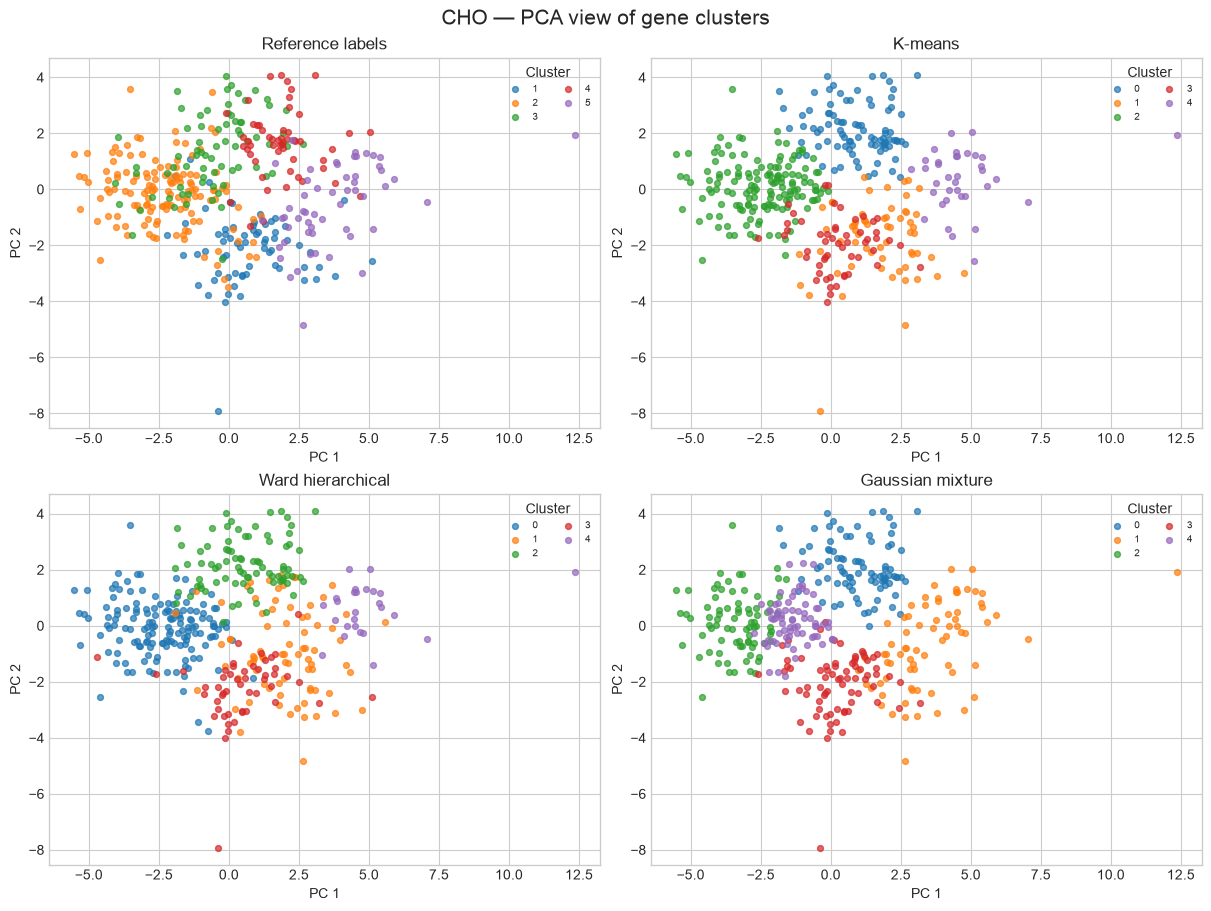

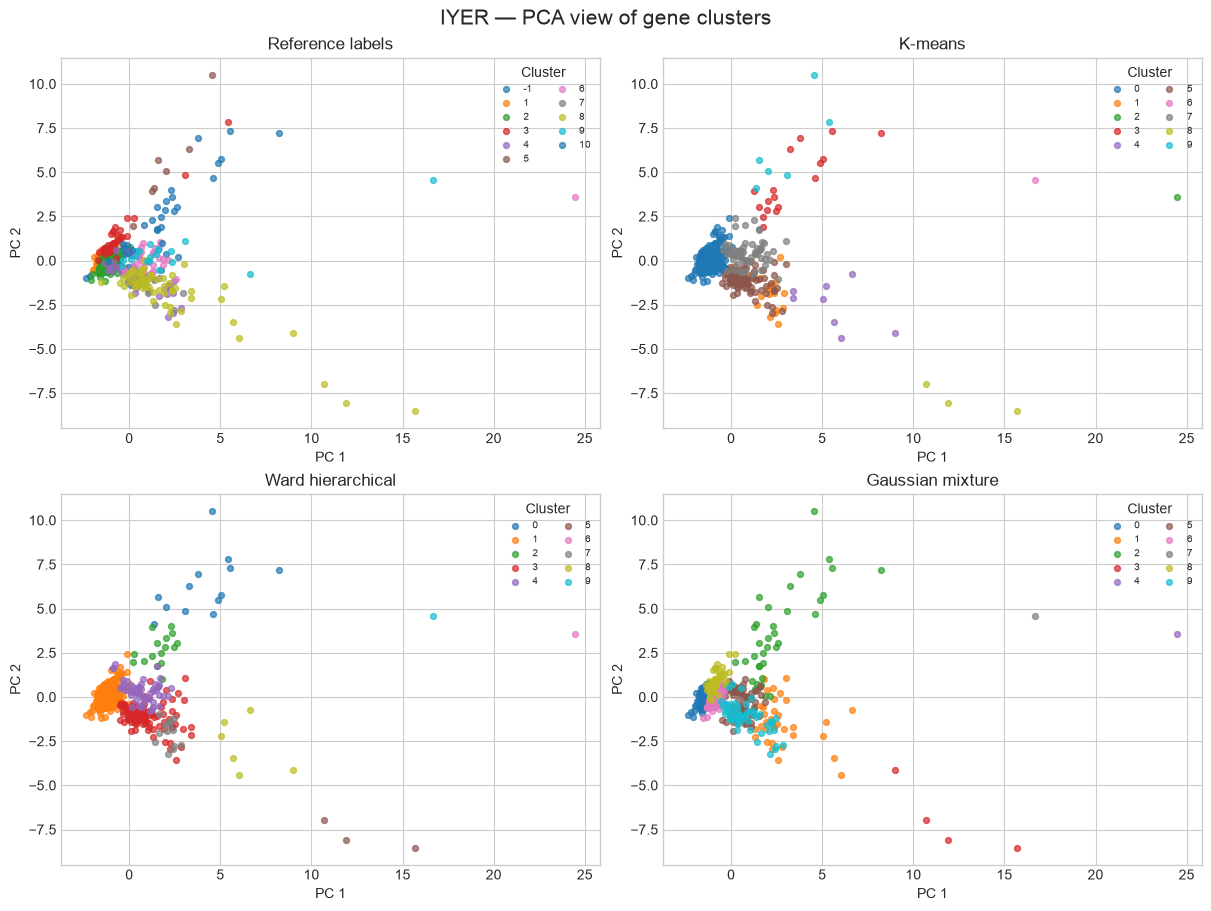

In [ ]:
for name, data in datasets.items():
    xy = data["pca_xy"]
    panels = {"Reference labels": data["truth"], **data["predictions"]}
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
    for ax, (title, labels) in zip(axes.flat, panels.items()):
        for cluster in sorted(np.unique(labels)):
            mask = labels == cluster
            ax.scatter(xy[mask, 0], xy[mask, 1], s=18, alpha=.7, label=str(cluster))
        ax.set(title=title, xlabel="PC 1", ylabel="PC 2")
        ax.legend(title="Cluster", fontsize=7, ncol=2)
    fig.suptitle(f"{name.upper()} -PCA view of gene clusters", fontsize=15)
    plt.show()

## saving the score table

In [11]:
out = DATA_DIR / "metrics.csv"
scores.to_csv(out, index=False)